### Q1. Consider the dataset Sacremento.csv. Ignoring the variable “zip”, consider “price” as the response variable and all other as features. With K-Fold cross-validation with Grid Search with parameters of your choice, evaluate r2 score with following algorithms:
    1. ElasticNet
    2. Random Forest
    3. XG Boost
    4. LightGBM

In [1]:
import numpy as np
import pandas as pd
import tqdm as tqdm
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import accuracy_score, r2_score, silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor, plot_tree, DecisionTreeClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.cluster import KMeans

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

# Then run your KMeans code
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv("Datasets/Sacremento.csv")
df.head()

,city,zip,beds,baths,sqft,type,price,latitude,longitude
0,SACRAMENTO,z95838,2,1.0,836,Residential,59222,38.631913,-121.434879
1,SACRAMENTO,z95823,3,1.0,1167,Residential,68212,38.478902,-121.431028
2,SACRAMENTO,z95815,2,1.0,796,Residential,68880,38.618305,-121.443839
3,SACRAMENTO,z95815,2,1.0,852,Residential,69307,38.616835,-121.439146
4,SACRAMENTO,z95824,2,1.0,797,Residential,81900,38.519470,-121.435768


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 932 entries, 0 to 931
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   city       932 non-null    object 
 1   zip        932 non-null    object 
 2   beds       932 non-null    int64  
 3   baths      932 non-null    float64
 4   sqft       932 non-null    int64  
 5   type       932 non-null    object 
 6   price      932 non-null    int64  
 7   latitude   932 non-null    float64
 8   longitude  932 non-null    float64
dtypes: float64(3), int64(3), object(3)
memory usage: 65.7+ KB


In [5]:
df.columns

Index(['city', 'zip', 'beds', 'baths', 'sqft', 'type', 'price', 'latitude',
       'longitude'],
      dtype='object')

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
X, y = df.drop(["zip", "price"],axis=1), df["price"]

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [9]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first').set_output(transform='pandas')
ct = make_column_transformer((ohe, make_column_selector(dtype_include='object')),
                             ('passthrough', make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')                                                       

In [10]:
X_train_transform = ct.fit_transform(X_train) 
X_test_transform = ct.transform(X_test)

C:\Users\adesh\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [11]:
lr = LinearRegression()
lr.fit(X_train_transform,y_train)
y_pred = lr.predict(X_test_transform)
r2_score(y_test, y_pred)

0.6472226812387275

In [12]:
ridge = Ridge()
ridge.fit(X_train_transform, y_train)
y_pred = ridge.predict(X_test_transform)
r2_score(y_test,y_pred)

0.6626396368590373

In [13]:
lasso = Lasso()
lasso.fit(X_train_transform,y_train)
y_pred = lasso.predict(X_test_transform)
r2_score(y_test,y_pred)

0.6477055367520563

In [14]:
en = ElasticNet()
en.fit(X_train_transform,y_train)
y_pred = en.predict(X_test_transform)
r2_score(y_test,y_pred)

0.618173357241194

# Elastic Net

In [15]:
model = ElasticNet()
scaler = StandardScaler()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("ElasticNet",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('ElasticNet', ElasticNet())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                        

In [16]:
Kfold = KFold(n_splits=5,shuffle=True, random_state=26)
params = { "ElasticNet__alpha": np.linspace(0.001,10,20),
           "ElasticNet__l1_ratio": np.linspace(0.001,1,20)}

gcv = GridSearchCV(pipe, param_grid=params, cv=Kfold, n_jobs=-1, scoring='r2')
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'ElasticNet__alpha': np.float64(0.5272631578947369), 'ElasticNet__l1_ratio': np.float64(0.9474210526315789)}
Best Score: 0.6607025330500205


# Lasso

In [17]:
model = Lasso()
scaler = StandardScaler()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("Lasso",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('Lasso', Lasso())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                                  

In [18]:
Kfold = KFold(n_splits=5,shuffle=True, random_state=26)
params = { "Lasso__alpha": np.linspace(0.001,10,20)}

gcv = GridSearchCV(pipe, param_grid=params, cv=Kfold, n_jobs=-1, scoring='r2')
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'Lasso__alpha': np.float64(10.0)}
Best Score: 0.6575869286387805


# Random Forest

In [19]:
model = RandomForestRegressor()
scaler = StandardScaler()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("RF",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('RF', RandomForestRegressor())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                     

In [20]:
kfold = KFold(shuffle=True, n_splits=5, random_state= 26)
params = { "RF__max_features":[3,4,5,6],
           "RF__max_depth" : [None, 5, 10 ,15],
           "RF__n_estimators" : [10,25,50,100],
           "RF__min_samples_split":[2,5,10,15]}
gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring='r2', n_jobs=-1)
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'RF__max_depth': 15, 'RF__max_features': 6, 'RF__min_samples_split': 5, 'RF__n_estimators': 50}
Best Score: 0.671904398471546


# XGBOOST

In [21]:
gbm = XGBRegressor()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("gbm",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('gbm', RandomForestRegressor())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                    

In [22]:
kfold = KFold(shuffle=True, n_splits=5, random_state= 26)
params = { "gbm__max_features":[3,4,5,6],
           "gbm__max_depth" : [None, 5, 10 ,15],
           "gbm__n_estimators" : [10,25,50,100]
         }
gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring='r2', n_jobs=-1)
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'gbm__max_depth': 15, 'gbm__max_features': 6, 'gbm__n_estimators': 100}
Best Score: 0.6695311783992848


# LightGBM

In [23]:
gbm = LinearRegression()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("gbm",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('gbm', RandomForestRegressor())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                    

In [24]:
kfold = KFold(shuffle=True, n_splits=5, random_state= 26)
params = { "gbm__max_features":[3,4,5,6],
           "gbm__max_depth" : [None, 5, 10 ,15],
           "gbm__n_estimators" : [10,25,50,100]
         }
gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring='r2', n_jobs=-1)
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'gbm__max_depth': 15, 'gbm__max_features': 5, 'gbm__n_estimators': 100}
Best Score: 0.668905445484131


# CatBoost

In [25]:
gbm = CatBoostRegressor()
pipe = Pipeline([("CT",ct),("Scaler",scaler),("gbm",model)])
pipe.get_params()

{'memory': None,
 'steps': [('CT',
   ColumnTransformer(transformers=[('onehotencoder',
                                    OneHotEncoder(drop='first',
                                                  handle_unknown='ignore',
                                                  sparse_output=False),
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F46D10>),
                                   ('passthrough', 'passthrough',
                                    <sklearn.compose._column_transformer.make_column_selector object at 0x000001F4B6F47A60>)],
                     verbose_feature_names_out=False)),
  ('Scaler', StandardScaler()),
  ('gbm', RandomForestRegressor())],
 'transform_input': None,
 'verbose': False,
 'CT': ColumnTransformer(transformers=[('onehotencoder',
                                  OneHotEncoder(drop='first',
                                                handle_unknown='ignore',
                    

In [26]:
kfold = KFold(shuffle=True, n_splits=5, random_state= 26)
params = { "gbm__max_features":[3,4,5,6],
           "gbm__max_depth" : [None, 5, 10 ,15],
           "gbm__n_estimators" : [10,25,50,100]
         }
gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring='r2', n_jobs=-1)
gcv.fit(X,y)
print("Best Params:",gcv.best_params_)
print("Best Score:",gcv.best_score_)

Best Params: {'gbm__max_depth': 15, 'gbm__max_features': 6, 'gbm__n_estimators': 50}
Best Score: 0.6746275047169966


## Q2. 
1. Consider the dataset Protein.xlsx. Find best K, for K-Means clustering on the basis of Silhouette Scores
2. State the number PCAs which provide 80% variation

In [31]:
df = pd.read_excel("Datasets/Protein.xlsx",index_col=0)
df.head()

,RedMeat,WhiteMeat,Eggs,Milk,Fish,Cereals,Starch,Nuts,Fr&Veg
Country,,,,,,,,,
Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
Belgium,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
Czechoslovakia,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25 entries, Albania to Yugoslavia
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   RedMeat    25 non-null     float64
 1   WhiteMeat  25 non-null     float64
 2   Eggs       25 non-null     float64
 3   Milk       25 non-null     float64
 4   Fish       25 non-null     float64
 5   Cereals    25 non-null     float64
 6   Starch     25 non-null     float64
 7   Nuts       25 non-null     float64
 8   Fr&Veg     25 non-null     float64
dtypes: float64(9)
memory usage: 2.0+ KB


In [33]:
df.isnull().sum().sum()

np.int64(0)

In [34]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)

In [35]:
scl_df.head()

,RedMeat,WhiteMeat,Eggs,Milk,Fish,Cereals,Starch,Nuts,Fr&Veg
Country,,,,,,,,,
Albania,0.082941,-1.794750,-2.224584,-1.179570,-1.225033,0.934804,-2.295965,1.247968,-1.378251
Austria,-0.282974,1.686446,1.245621,0.400468,-0.655111,-0.395051,-0.422218,-0.910790,0.092789
Belgium,1.119699,0.387905,1.062979,0.055732,0.064791,-0.525246,0.889405,-0.499598,-0.076947
Bulgaria,-0.618396,-0.523837,-1.220051,-1.265754,-0.925074,2.273959,-1.983674,0.322786,0.036210
Czechoslovakia,-0.039031,0.968104,-0.124197,-0.662467,-0.685107,0.190830,0.452198,-1.013588,-0.076947


In [36]:
ks = np.arange(2,10)
score = []
for k in tqdm.tqdm(ks):
    kmeans = KMeans(n_clusters=k, random_state=26)
    kmeans.fit(scl_df)
    sc = silhouette_score(scl_df,kmeans.labels_)
    score.append([k, sc])
df_score = pd.DataFrame(score, columns=["K","Score"])
df_score.sort_values("Score",ascending=False)

100%|██████████| 8/8 [00:00<00:00, 19.79it/s]


,K,Score
0,2,0.327108
3,5,0.263945
4,6,0.252868
5,7,0.226217
6,8,0.217537
1,3,0.211785
2,4,0.198055
7,9,0.183742


In [37]:
from sklearn.decomposition import PCA

In [38]:
pca = PCA(n_components=0.80)
pca.fit(scl_df)
print("Number of PCs for 80% variation:", pca.n_components_)

Number of PCs for 80% variation: 4


## Q3. Consider the dataset Vehicle.csv. Consider the variable “Class” as response variable. 
1. With Grid Search for Decision Tree considering parameter values for max_depth as [2,4,6] , min_samples_split  as [2,3,5] and min_samples_leaf as [1,3,5], find best parameter set on the basis of log loss.
2. With Grid Search for Random Forest considering parameter values for max_features=[2,3,4,5]
3. With Grid Search for Logistic Regression considering parameter values of solvers

# Decision Tree

In [39]:
df = pd.read_csv("Datasets/Vehicle.csv")
df.head()

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


In [40]:
df.isnull().sum().sum()

np.int64(0)

In [41]:
X, y = df.drop("Class",axis=1), df["Class"]

In [42]:
scaler = StandardScaler()
dt = DecisionTreeClassifier()
pipe = Pipeline([("scaler",scaler),("dt",dt)])
pipe.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()), ('dt', DecisionTreeClassifier())],
 'transform_input': None,
 'verbose': False,
 'scaler': StandardScaler(),
 'dt': DecisionTreeClassifier(),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'dt__ccp_alpha': 0.0,
 'dt__class_weight': None,
 'dt__criterion': 'gini',
 'dt__max_depth': None,
 'dt__max_features': None,
 'dt__max_leaf_nodes': None,
 'dt__min_impurity_decrease': 0.0,
 'dt__min_samples_leaf': 1,
 'dt__min_samples_split': 2,
 'dt__min_weight_fraction_leaf': 0.0,
 'dt__monotonic_cst': None,
 'dt__random_state': None,
 'dt__splitter': 'best'}

In [43]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=26)
params = { "dt__max_depth" : [2,4,6], #max_depth as [2,4,6] , min_samples_split as [2,3,5] and min_samples_leaf as [1,3,5]
           "dt__min_samples_leaf" : [1,3,5],
           "dt__min_samples_split": [2,3,5]
         }

gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring="neg_log_loss")

gcv.fit(X, y)

print("Best Params:", gcv.best_params_)
print("Best Score:", gcv.best_score_)

Best Params: {'dt__max_depth': 2, 'dt__min_samples_leaf': 1, 'dt__min_samples_split': 2}
Best Score: -1.0906408681841007


# Random Forest Classifier

In [ ]:
scaler = StandardScaler()
rf = RandomForestClassifier()
pipe = Pipeline([("scaler",scaler),("rf",rf)])
pipe.get_params()

In [ ]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=26)
params = { "rf__max_features" : [2,3,5] # max_features=[2,3,4,5]
         }

gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring="neg_log_loss")

gcv.fit(X, y)

print("Best Params:", gcv.best_params_)
print("Best Score:", gcv.best_score_)

# Logistic Regression

In [ ]:
scaler = StandardScaler()
lr = LogisticRegression()
pipe = Pipeline([("scaler",scaler),("lr",lr)])
pipe.get_params()

In [ ]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=26)
params = { "lr__solver" : ['newton-cg', 'sag', 'saga','lbfgs'] # max_features=[2,3,4,5]
         }

gcv = GridSearchCV(pipe, param_grid=params, cv = kfold, scoring="neg_log_loss")

gcv.fit(X, y)

print("Best Params:", gcv.best_params_)
print("Best Score:", gcv.best_score_)

# Q4. Consider the time series monthly-beer-production-in-austr.csv. Try the following:
1. Check whether the series is stationary
2. ARIMA models
3. Smoothing models


In [3]:
df = pd.read_csv("Datasets/monthly-beer-production-in-austr.csv",index_col=0)
df.head()

,Monthly beer production
Month,
1956-01,93.2
1956-02,96.0
1956-03,95.2
1956-04,77.1
1956-05,70.9


In [4]:
df.index = pd.to_datetime(df.index).to_period("M")

In [5]:
df.index.dtype

period[M]

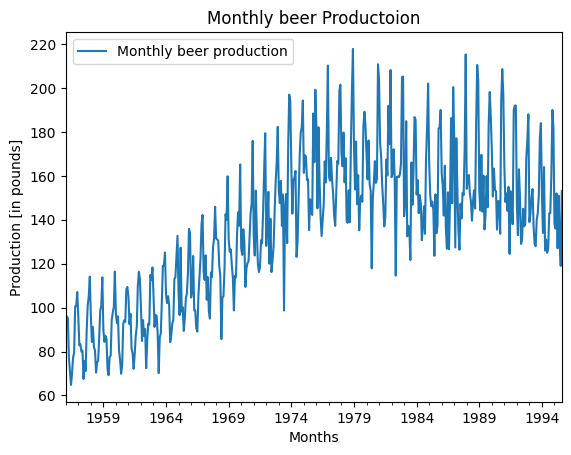

In [6]:
df.plot()
plt.title("Monthly beer Productoion")
plt.xlabel("Months")
plt.ylabel("Production [in pounds]")
plt.show()

# resampling

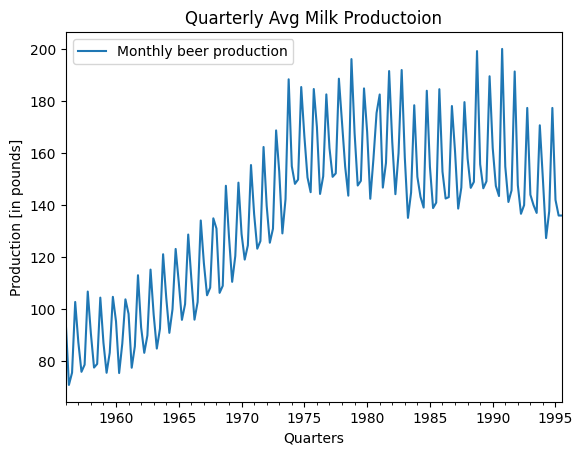

In [7]:
df_q = df.resample("Q").mean() #downsampling
df_q.plot()
plt.title("Quarterly Avg Milk Productoion")
plt.xlabel("Quarters")
plt.ylabel("Production [in pounds]")
plt.show()

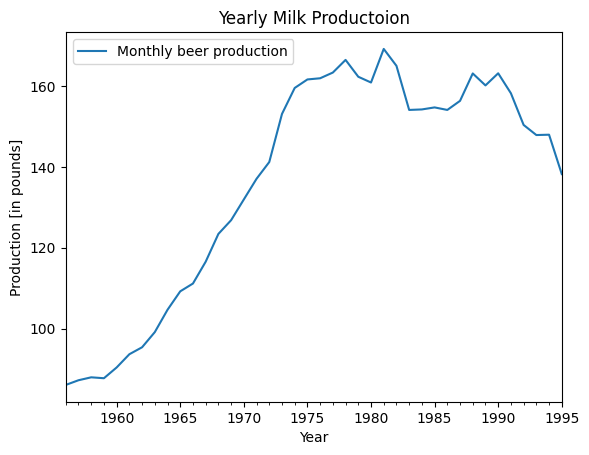

In [8]:
df_y = df.resample("Y").mean()
df_y.plot()
plt.title("Yearly Milk Productoion")
plt.xlabel("Year")
plt.ylabel("Production [in pounds]")
plt.show()

In [9]:
df

,Monthly beer production
Month,
1956-01,93.2
1956-02,96.0
1956-03,95.2
1956-04,77.1
1956-05,70.9
...,...
1995-04,127.0
1995-05,151.0
1995-06,130.0


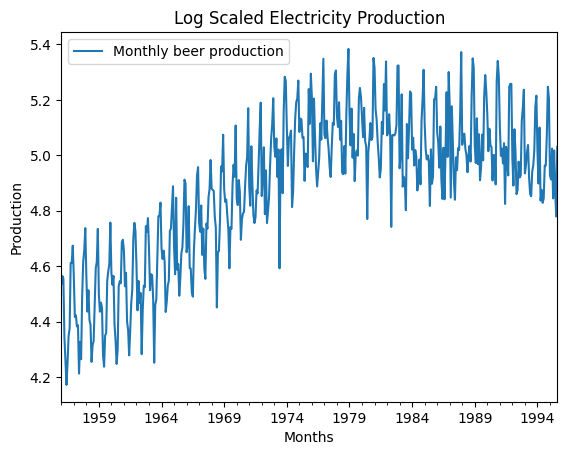

In [10]:
# logarithmic graph
df["Monthly beer production"] = np.log(df["Monthly beer production"])
df.plot()
plt.title("Log Scaled Electricity Production")
plt.xlabel("Months")
plt.ylabel("Production")
plt.show()

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [12]:
df.columns

Index(['Monthly beer production'], dtype='object')

In [13]:
df = pd.read_csv("Datasets/monthly-beer-production-in-austr.csv",index_col=0)
df.head()

,Monthly beer production
Month,
1956-01,93.2
1956-02,96.0
1956-03,95.2
1956-04,77.1
1956-05,70.9


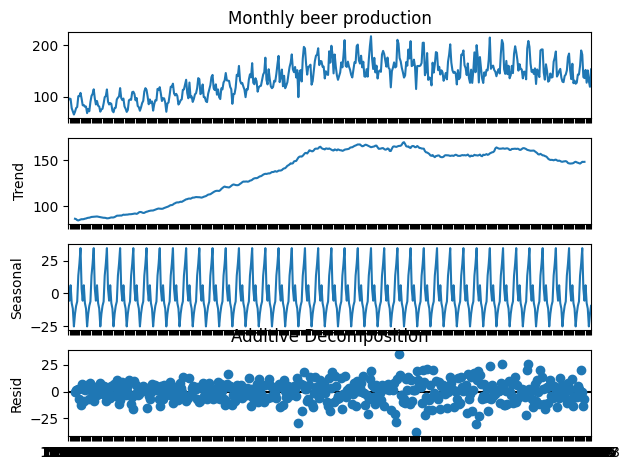

In [14]:
series = df["Monthly beer production"]
res = seasonal_decompose(series, model = 'additive', period=12)
res.plot()
plt.title("Additive Decomposition")
plt.show()

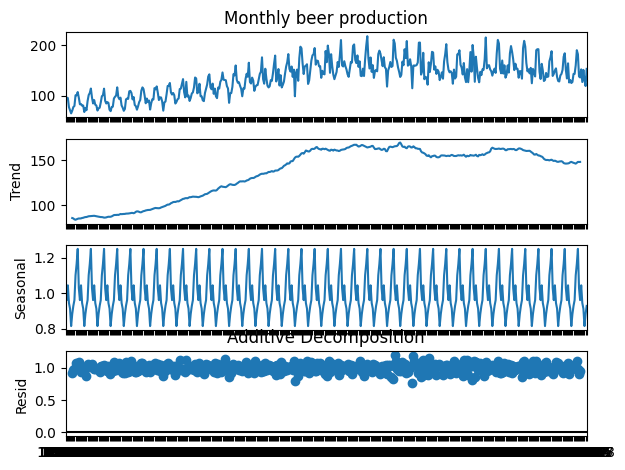

In [15]:
series = df["Monthly beer production"]
res = seasonal_decompose(series, model = 'Multiplicative', period=12)
res.plot()
plt.title("Additive Decomposition")
plt.show()

In [16]:
from sklearn.metrics import root_mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import statsmodels.api as sm


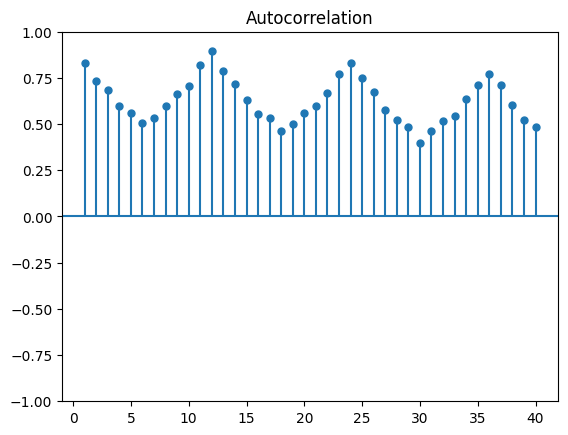

In [17]:
plot_acf(df["Monthly beer production"], lags=40, alpha=None,zero=False)
plt.show()

In [18]:
res = adfuller(df["Monthly beer production"], maxlag=10,result_object=True)
print("P value : ", res[1])
if res[1] < 0.05:
    print("Time Series is Stationary")
else:
    print("Time Series is not Stationary")

P value :  0.3836382775639326
Time Series is not Stationary


In [19]:
diff_1 = df["Monthly beer production"].diff().dropna()
res = adfuller(diff_1, maxlag=10, result_object=True)
print("P VAlue : ", res[1])
if  res[1] < 0.05:
    print("Time Series is Stationary")
else:
    print("Time Series is not Stationary")

P VAlue :  0.0
Time Series is Stationary


# Arima

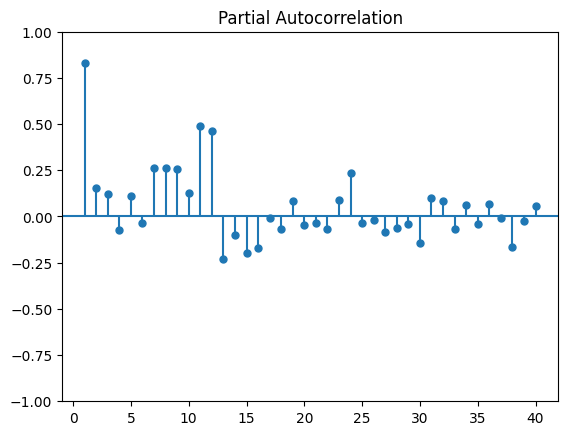

In [20]:
plot_pacf(df["Monthly beer production"], lags=40, alpha= None, zero=False)
plt.show()

In [21]:
y = df["Monthly beer production"]
y_train = df[:-12]
y_test = df[-12:]

In [22]:
model = ARIMA(y_train, order=(2,1,1)) #p,d,q
model_fit = model.fit()
print("Coefficients %s" % model_fit.params)
pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)
error = root_mean_squared_error(y_test, pred)
print("Test RMSE : %.2f" % error)

C:\Users\adesh\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\adesh\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\adesh\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Coefficients ar.L1      -0.974617
ar.L2      -0.314378
ma.L1       0.745429
sigma2    343.799550
dtype: float64
Test RMSE : 23.33


<Axes: xlabel='Month'>

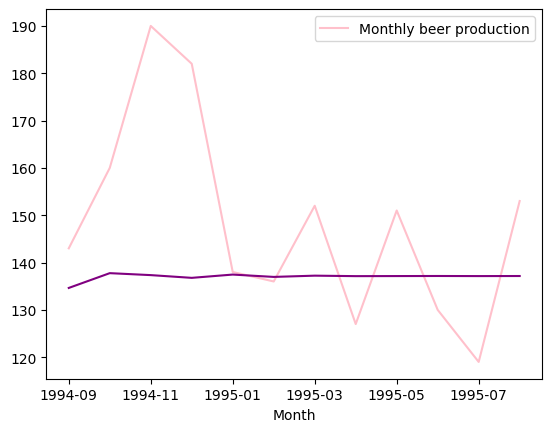

In [25]:
pred.index = y_test.index
y_test.plot(color='pink')
pred.plot(color='purple')

In [31]:
from pmdarima.arima import auto_arima

In [32]:
auto_model = auto_arima(y_train, trace=True, error_action="ignore", suppress_warning=True)
best_order = auto_model.order
print("Best Order found:", best_order)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=3952.461, Time=1.49 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=4070.292, Time=0.16 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=4047.060, Time=0.31 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=4037.367, Time=0.33 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=4068.306, Time=0.15 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=4013.976, Time=1.05 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=4028.080, Time=0.92 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=3953.392, Time=1.25 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=3954.005, Time=1.46 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=3957.114, Time=0.62 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=3960.438, Time=1.02 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=3958.799, Time=1.23 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.86 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=3953.794, Time=0.67 sec

Best model:  ARIMA(2,1,2)(0,0,0)[0] i

In [33]:
y_model = auto_arima(y_train, trace=True, error_action='ignore', suppress_warnings=True,seasonal=True,m=12)


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=3469.256, Time=5.16 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=4070.292, Time=0.13 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=3807.869, Time=1.58 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=3839.739, Time=1.01 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=4068.306, Time=0.13 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=3799.097, Time=2.05 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=inf, Time=4.50 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=3506.513, Time=14.81 sec
 ARIMA(2,1,2)(1,0,2)[12] intercept   : AIC=3467.551, Time=14.08 sec
 ARIMA(2,1,2)(0,0,2)[12] intercept   : AIC=3715.554, Time=5.72 sec
 ARIMA(2,1,2)(2,0,2)[12] intercept   : AIC=inf, Time=16.90 sec
 ARIMA(1,1,2)(1,0,2)[12] intercept   : AIC=inf, Time=13.15 sec
 ARIMA(2,1,1)(1,0,2)[12] intercept   : AIC=3489.462, Time=11.07 sec
 ARIMA(3,1,2)(1,0,2)[12] intercept   : AIC=3469.045, Time=15.80 sec
 ARIMA(2,1,3)(1,0,2)[12] int